In [39]:
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import train_test_split

In [40]:
# 1. Cargar dataset observable y filtrar SKU_101
df = pd.read_csv("data/ecommerce_panel.csv")
sku1 = df[df["sku_id"] == "SKU_101"].copy()

# Variables predictoras observables sin instrumento
features = [
    "effective_price",
    "competitor_price",
    "is_weekend",
    "is_peak_event",
    "discount_pct",
]
target = "units_sold"

X = sku1[features]
y = sku1[target]

# Split reproducible con semilla 1897
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 1897)


In [41]:
# 2. Entrenar modelos ML estándar
rf_model = RandomForestRegressor(n_estimators = 300, random_state = 1897, n_jobs = 1)
hgb_model = HistGradientBoostingRegressor(random_state = 1897)

rf_model.fit(X_train, y_train)
hgb_model.fit(X_train, y_train)

for name, model in [("Random Forest", rf_model), ("HistGradientBoosting", hgb_model)]:
    preds = model.predict(X_test)
    rmse = root_mean_squared_error(y_test, preds)
    mae = mean_absolute_error(y_test, preds)
    print(f"{name} -> Test RMSE: {rmse:.2f} | Test MAE: {mae:.2f}")

Random Forest -> Test RMSE: 18.63 | Test MAE: 13.96
HistGradientBoosting -> Test RMSE: 16.66 | Test MAE: 12.56


In [42]:
# 3. Grilla contrafactual idéntica a la de R, con precios de 60 a 200 cada 2 USD
base_price = sku1["base_price"].iloc[0]
comp_ref = sku1["competitor_price"].mean()
price_grid = np.arange(60, 202, 2)

grid_df = pd.DataFrame({
    "effective_price": price_grid,
    "competitor_price": comp_ref,
    "is_weekend": 0,
    "is_peak_event": 0,
    "discount_pct": np.maximum(0.0, (base_price - price_grid) / base_price),
})

grid_df["q_hat_rf"] = rf_model.predict(grid_df[features])
grid_df["q_hat_hgb"] = hgb_model.predict(grid_df[features])

# Unir con la curva causal generada en R para comparar lado a lado
causal_grid = pd.read_csv("outputs/demanda_contrafactual_causal_sku101.csv")
comparison_df = grid_df.merge(causal_grid[["effective_price", "q_hat_causal", "q_hat_ingenuo"]],
    on="effective_price",
    how="left",
)
    

comparison_df.head(10)

,effective_price,competitor_price,is_weekend,is_peak_event,discount_pct,q_hat_rf,q_hat_hgb,q_hat_causal,q_hat_ingenuo
0,60,120.266389,0,0,0.500000,144.9,134.891256,356.085383,232.779947
1,62,120.266389,0,0,0.483333,144.9,134.891256,330.793157,220.705988
2,64,120.266389,0,0,0.466667,144.9,134.891256,308.017122,209.612475
3,66,120.266389,0,0,0.450000,144.9,134.891256,287.439623,199.392759
4,68,120.266389,0,0,0.433333,144.9,134.891256,268.791117,189.954563
5,70,120.266389,0,0,0.416667,144.9,134.891256,251.841737,181.217690
6,72,120.266389,0,0,0.400000,144.9,134.891256,236.394534,173.112153
7,74,120.266389,0,0,0.383333,144.9,134.891256,222.280010,165.576639
8,76,120.266389,0,0,0.366667,144.9,134.891256,209.351684,158.557232
9,78,120.266389,0,0,0.350000,144.9,134.891256,197.482462,152.006358


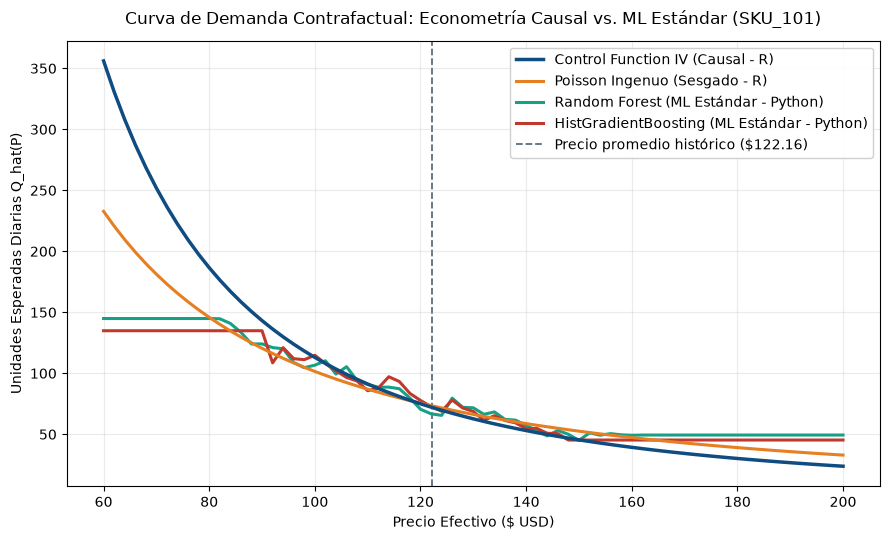

In [46]:
# 4. Graficando
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(
    comparison_df["effective_price"],
    comparison_df["q_hat_causal"],
    label="Control Function IV (Causal - R)",
    color="#0F4C81",  # Azul profundo
    linewidth=2.5,
    linestyle="-",
    zorder=4,
)
ax.plot(
    comparison_df["effective_price"],
    comparison_df["q_hat_ingenuo"],
    label="Poisson Ingenuo (Sesgado - R)",
    color="#E67E22",  # Naranja intenso
    linewidth=2.2,
    linestyle="-",
    zorder=3,
)
ax.plot(
    comparison_df["effective_price"],
    comparison_df["q_hat_rf"],
    label="Random Forest (ML Estándar - Python)",
    color="#16A085",  # Verde esmeralda
    linewidth=2.2,
    linestyle="-",
    zorder=2,
)
ax.plot(
    comparison_df["effective_price"],
    comparison_df["q_hat_hgb"],
    label="HistGradientBoosting (ML Estándar - Python)",
    color="#C0392B",  # Rojo carmesí
    linewidth=2.2,
    linestyle="-",
    zorder=2,
)

# Referencia del precio promedio histórico de SKU_101
mean_price = sku1["effective_price"].mean()
ax.axvline(
    mean_price,
    color="#5D6D7E",
    linestyle="--",
    linewidth=1.3,
    label=f"Precio promedio histórico (${mean_price:.2f})",
    zorder=1,
)

ax.set_title(
    "Curva de Demanda Contrafactual: Econometría Causal vs. ML Estándar (SKU_101)",
    fontsize=12,
    pad=12,
)
ax.set_xlabel("Precio Efectivo ($ USD)")
ax.set_ylabel("Unidades Esperadas Diarias Q_hat(P)")
ax.legend(frameon=True, facecolor="white", framealpha=0.92)
ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.savefig("outputs/counterfactual_demand_causal_vs_ml_py.png", dpi=300)
plt.show()



Optimizamos el precio calculando el costo marginal promedio de SKU_101, obteniendo las curvas de margen bruto esperado, calcula el precio óptimo y evalúa cuánto margen real generaría si lo llevamos a un mundo donde la elasticidad poblacional es de -2.15

Costo marginal promedio SKU_101: $58.58 USD

--- Resumen de Optimización de Precios (SKU_101) ---
                                     Modelo  Precio Óptimo Sugerido (P*)  Margen Esperado por el Modelo ($/día)  Margen Real en el Mercado ($/día)
           Control Function IV (Causal - R)                          106                                4700.63                            4656.07
              Poisson Ingenuo (Sesgado - R)                          152                                4804.42                            4226.19
       Random Forest (ML Estándar - Python)                          200                                6983.24                            3546.27
HistGradientBoosting (ML Estándar - Python)                          200                                6404.54                            3546.27
         Óptimo Teórico Real (Ground Truth)                          110                                4662.35                            4662.35


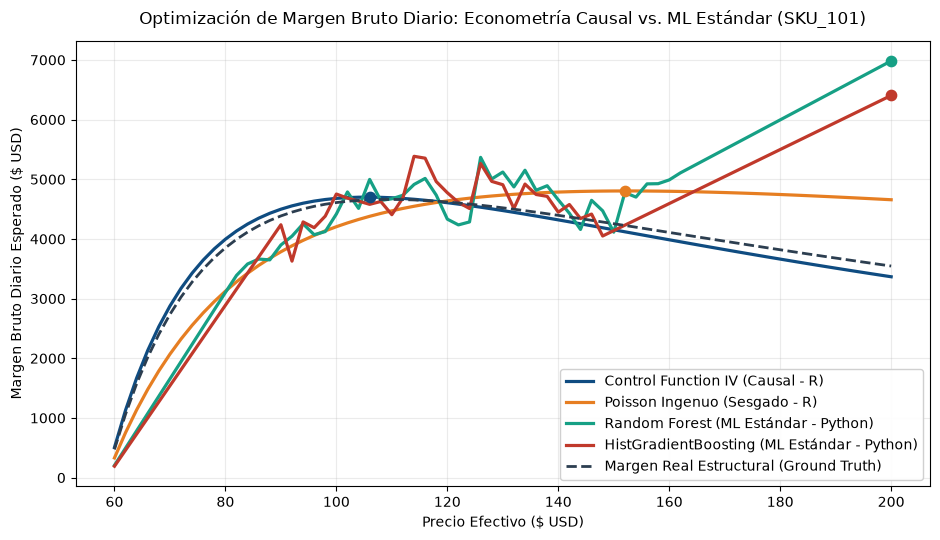

In [47]:
# Costo marginal
mc_ref = sku1["marginal_cost"].mean()
print(f"Costo marginal promedio SKU_101: ${mc_ref:.2f} USD")

# Margen bruto diario esperado bajo cada modelo
models = {
    "causal": ("q_hat_causal", "Control Function IV (Causal - R)", "#0F4C81"),
    "ingenuo":("q_hat_ingenuo", "Poisson Ingenuo (Sesgado - R)", "#E67E22"),
    "rf": ("q_hat_rf", "Random Forest (ML Estándar - Python)", "#16A085"),
    "hgb": ("q_hat_hgb", "HistGradientBoosting (ML Estándar - Python)", "#C0392B"),
}

for key, (q_col, _, _) in models.items():
    comparison_df[f"margin_{key}"] = (
        comparison_df["effective_price"] - mc_ref
    ) * comparison_df[q_col]

# Evaluación vs DGP real -2.15
comp_ref = sku1["competitor_price"].mean()
true_alpha = 11.5
true_price_elast = -2.15
true_cross_elast = 0.65

comparison_df["q_true"] = np.exp(
    true_alpha
    + true_price_elast * np.log(comparison_df["effective_price"])
    + true_cross_elast * np.log(comp_ref)
)
comparison_df["margin_true"] = (
    comparison_df["effective_price"] - mc_ref
) * comparison_df["q_true"]

# Tabla summarise
summary_rows = []
for key, (q_col, label, _) in models.items():
    idx_opt = comparison_df[f"margin_{key}"].idxmax()
    p_star = comparison_df.loc[idx_opt, "effective_price"]
    est_margin = comparison_df.loc[idx_opt, f"margin_{key}"]
    real_margin = comparison_df.loc[idx_opt, "margin_true"]
    summary_rows.append({
        "Modelo": label,
        "Precio Óptimo Sugerido (P*)": round(p_star, 2),
        "Margen Esperado por el Modelo ($/día)": round(est_margin, 2),
        "Margen Real en el Mercado ($/día)": round(real_margin, 2),
    })

# Óptimo teórico del mercado
idx_true = comparison_df["margin_true"].idxmax()
summary_rows.append({
    "Modelo": "Óptimo Teórico Real (Ground Truth)",
    "Precio Óptimo Sugerido (P*)": round(comparison_df.loc[idx_true, "effective_price"], 2),
    "Margen Esperado por el Modelo ($/día)": round(comparison_df.loc[idx_true, "margin_true"], 2),
    "Margen Real en el Mercado ($/día)": round(comparison_df.loc[idx_true, "margin_true"], 2),
})

opt_summary = pd.DataFrame(summary_rows)
print("\n--- Resumen de Optimización de Precios (SKU_101) ---")
print(opt_summary.to_string(index = False))

# Gráfico
fig, ax = plt.subplots(figsize = (9.5, 5.5))

for key, (_, label, color) in models.items():
    ax.plot(
        comparison_df["effective_price"],
        comparison_df[f"margin_{key}"],
        label=label,
        color=color,
        linewidth=2.3,
    )
    # Marcar el punto máximo (P*) de cada curva
    idx_max = comparison_df[f"margin_{key}"].idxmax()
    ax.scatter(
        comparison_df.loc[idx_max, "effective_price"],
        comparison_df.loc[idx_max, f"margin_{key}"],
        color=color,
        s=55,
        zorder=5,
    )

# Curva real de referencia en gris oscuro punteado
ax.plot(
    comparison_df["effective_price"],
    comparison_df["margin_true"],
    label="Margen Real Estructural (Ground Truth)",
    color="#2C3E50",
    linestyle="--",
    linewidth=2.0,
)

ax.set_title(
    "Optimización de Margen Bruto Diario: Econometría Causal vs. ML Estándar (SKU_101)",
    fontsize=12,
    pad=12,
)
ax.set_xlabel("Precio Efectivo ($ USD)")
ax.set_ylabel("Margen Bruto Diario Esperado ($ USD)")
ax.legend(frameon=True, facecolor="white", framealpha=0.92)
ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.savefig("outputs/gross_margin_optimization_causal_vs_ml_py.png", dpi=300)
plt.show()

